### Goals:
- Predict a continuous output (y) from input features (x)

In [12]:
# Firstly import lib
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

from sklearn.metrics import mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression

import sys, os

sys.path.insert(0, os.path.abspath(''))

[ 84  96 108 126 144 176 226]
[13.5 15.  17.  17.  18.  20.  23. ]


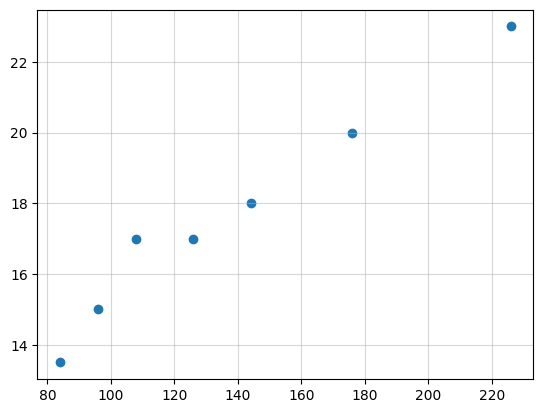

In [2]:
# assume an available sample of dots, which peforms price and area of houses
x = np.array([84, 96, 108, 126, 144, 176, 226])
y = np.array([13.5, 15, 17, 17, 18, 20, 23])

print(x)
print(y)
plt.scatter(x, y)
plt.grid(True, linestyle='-', alpha=0.5)
plt.show()

## A. Linear Regression

### The primary function, high applicability and connectivity with esential components of Regression and ML
- Assuming that the output value y is a linear combination of the features
$$
\hat{y} = w_0 + w_1x_1 + w_2x_2 + \dots + w_nx_n = \mathbf{w}^T \mathbf{x} + b
$$
- At that point, the model will learn the weights by minimising MSE
$$
\text{MSE} = \frac{1}{N} \sum (y_i - \hat{y}_i)^2
$$
- In case $X^T X$ is an invertible matrix, with small elements (n), the normal eqn is direct and effective:
$$
w^* = (X^T X)^{-1} X^T y
$$

In [3]:
# Observating that we have 7 elements
print(len(x), len(x) == len(y))

# Step 1: Create matrix of X
X = np.column_stack((np.ones(len(x)), x))
print(X)

# Step 2: Applicating the normal eqn 
w = np.linalg.inv(X.T @ X) @ X.T @ y

print(f"w0 (Intercept): {w[0]:.3f}")
print(f"w1 (Slope):     {w[1]:.3f}")

y_pred = X @ w
print("\nGiá trị dự đoán:", np.round(y_pred, 2))

# Evaluate use rmse
from src.regression import compute_mse

mse = compute_mse(y, y_pred=y_pred)
print("MSE:", mse)


7 True
[[  1.  84.]
 [  1.  96.]
 [  1. 108.]
 [  1. 126.]
 [  1. 144.]
 [  1. 176.]
 [  1. 226.]]
w0 (Intercept): 9.155
w1 (Slope):     0.062

Giá trị dự đoán: [14.35 15.1  15.84 16.95 18.07 20.05 23.14]
MSE: 0.3021469543840477


## Using Linear Regression to fit the sample data

We fit a line $\hat{y} = w x + b$ to the house-price data by minimising the Mean Squared Error (MSE):

$$MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2$$

In [4]:
# Fit the model with scikit-learn
# sklearn expects 2D input for X: shape (n_samples, n_features)
X = np.array(x).reshape(-1, 1)
# print(X)
y_arr = np.array(y)

model = LinearRegression()
model.fit(X, y_arr)

w = model.coef_[0]
b = model.intercept_
print(f'Model: price = {w:.4f} * area + {b:.4f}')

Model: price = 0.0619 * area + 9.1547


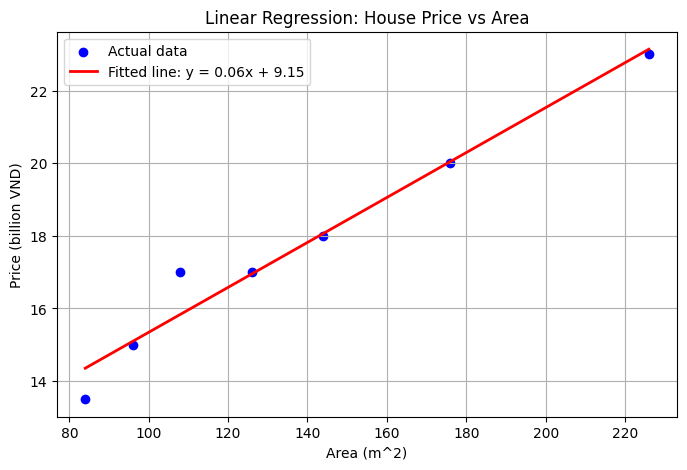

In [5]:
# Visualisation: data points, fitted line and predictions
y_pred = model.predict(X)

plt.figure(figsize=(8, 5))
plt.scatter(x, y, color='blue', label='Actual data')
plt.plot(x, y_pred, color='red', linewidth=2, label=f'Fitted line: y = {w:.2f}x + {b:.2f}')

plt.xlabel('Area (m^2)')
plt.ylabel('Price (billion VND)')
plt.title('Linear Regression: House Price vs Area')
plt.legend()
plt.grid(True)
plt.show()

MSE is optimal for use as a loss function and for model optimisation because it:
- Has a smooth derivative.
- Is computationally efficient.
- Magnifies large errors.

However, since the errors are squared, the units of measurement are also squared. To address this, RMSE (Root Mean Squared Error) is used to measure the average magnitude of the error between the model's predicted values ​​and the actual values.
$$
RMSE = \sqrt{MSE}
$$

To assess how well a model explains the overall picture, a metric called R-squared is used additionally, which is calculated according to the following formula:
$$
R^2 = 1 - \frac{SS_{res}}{SS_{tot}} = \frac{SS_{exp}}{SS_{tot}}
$$
While
$$
SS_{res} = \sum_{i=1}^{N} (y_i - \hat{y}_i)^2,SS_{tot} = \sum_{i=1}^{N} (y_i - \bar{y})^2,SS_{exp} = \sum_{i=1}^2
$$
For instance, when $R^2 = 95\%$, it means model can explain $95\%$ fluctuation in housing prices

In [6]:
sk_mse = mean_squared_error(y, y_pred)
print(sk_mse, mse)

sk_r2 = r2_score(y, y_pred)
print(sk_r2)

0.30214695438404776 0.3021469543840477
0.9643677478584396


In real case, Data dimension intended for use is typically stripped of components that are unnecessary or have little impact on the overall dataset. The more redundant dimension of data is removed, the more computational performance is improved.

## B. Gradient Descent

### Iteratively update the weights (w) along the surface of the loss function:
$$
w \leftarrow w - \eta \cdot \nabla_w L(w)
$$

With $\eta$ as learning rate and $\nabla_w L(w)$ is derivative of loss function

Epoch    0 | MSE: 319.7500 | w0: 0.00 | w1: 0.0051
Epoch   20 | MSE: 64.9854 | w0: 0.00 | w1: 0.0722
Epoch   40 | MSE: 18.9810 | w0: 0.00 | w1: 0.1008
Epoch   60 | MSE: 10.6736 | w0: 0.00 | w1: 0.1129
Epoch   80 | MSE: 9.1735 | w0: 0.00 | w1: 0.1180
--------------------------------------------------
Final result: y = 0.001 + 0.1201x


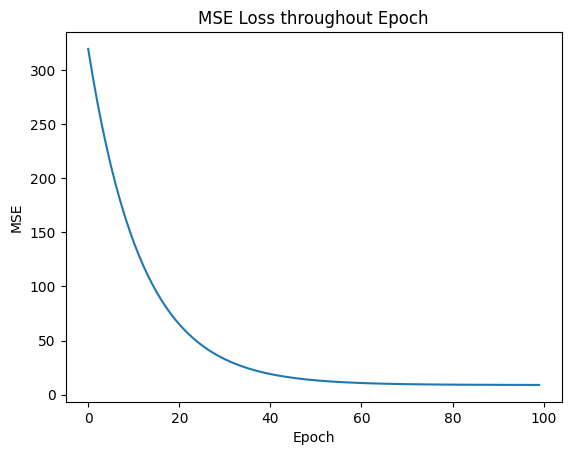

In [7]:
# Reuse available material
# print(x, y)
X = np.column_stack((np.ones(len(x)), x))
# print(X)

from src.regression import gradient_descent
w_optimal, history = gradient_descent(X, y, lr=0.000001, epochs=100, save_history=True)

plt.plot(history)
plt.title("MSE Loss throughout Epoch")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.show()

In this case, learning rate must be very-small-value. Since the input variable ($x$) is large, while we use $MSE$ as loss function $L$, gradient of loss fuction become:
$$
\nabla_w L(w) = \frac{2}{N} X^T(Xw -y)
$$
Assuming $w=0$, gradient value now become $\frac{2}{N} X^T(-y)$. The label value, approaching 200 leads gradient value approaching 10000, step $\Delta w$ leaps $100, -200, 400, -800$ with $\eta=0.01$

To handle the issue of weight values ​​diverging, the training input value is usually scaled befor training. Why don't we start with $[0, 1]$ scaling right this moment?

In [8]:
from src.regression import scale_zerone

print(x)
x_scaled, x_min, x_range = scale_zerone(x.reshape(-1, 1))
print(x_scaled.flatten())

[ 84  96 108 126 144 176 226]
[0.         0.08450704 0.16901408 0.29577465 0.42253521 0.64788732
 1.        ]


Epoch    0 | MSE: 319.7500 | w0: 3.53 | w1: 1.5066
Epoch    4 | MSE: 39.9133 | w0: 11.14 | w1: 4.8443
Epoch    8 | MSE: 5.5678 | w0: 13.76 | w1: 6.1121
Epoch   12 | MSE: 1.3036 | w0: 14.64 | w1: 6.6483
Epoch   16 | MSE: 0.7322 | w0: 14.92 | w1: 6.9219
--------------------------------------------------
Final result: y = 14.972 + 7.0587x


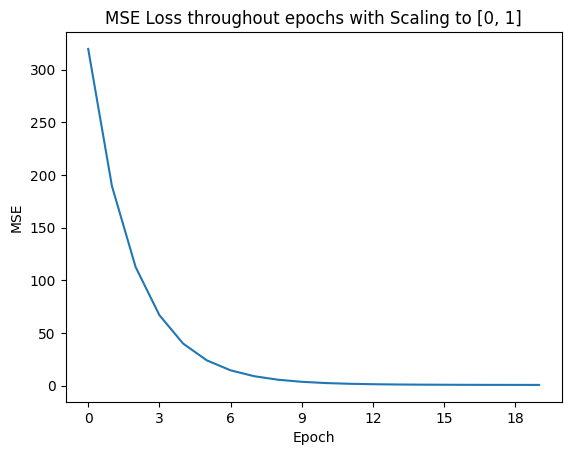

In [13]:
X_scaled = np.column_stack((np.ones(len(x_scaled)), x_scaled))
w, history = gradient_descent(X_scaled, y, lr=0.1, epochs=20, save_history=True)
plt.plot(history)
plt.title("MSE Loss throughout epochs with Scaling to [0, 1]")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.gca().xaxis.set_major_locator(ticker.MaxNLocator(integer=True))
plt.show()

This method, in academic terms, is called **min-max scaling**.

## Regularisation
To prevent overfitting, add a penalty on weights

### Overfitting?
In field of Machine Learning, a model becomes "overfitted" when it learns the training data too thoroughly—to the point where it also captures "noise" and trivial, meaningless details. The result: the model achieves an exceptionally high score on the training set (sometimes even 100%), but performs poorly when applied to real-world predictions (the test set).

Preventing overfitting ensures that a model learns the underlying trends in the data rather than the data itself. These trends—governed by specific mathematical principles—manifest themselves across a sufficiently large number of examples. Furthermore, overfitting prevention helps eliminate noisy or redundant data that may have persisted despite standard data preprocessing steps.

Usually has two method: Ridge &ndash; $L2$ and  Lasso &ndash; $L1$
$$
L_2 = MSE + \lambda \sum w_i^2, L_1 = MSE + \lambda \sum |w_i|

In [29]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
np.random.seed(42)
N = 100
X_raw = np.random.randn(N, 5) 
# Real rule: y = 5*x1 - 2*x2 + noise
y_r = 5 * X_raw[:, 0] - 2 * X_raw[:, 1] + np.random.randn(N) * 2 

# print(X_raw)
# print(y_r)
print(len(X_raw))
X_rscaled, _, __ =  scale_zerone(X_raw)
# print(X_rscaled)
# No penalty
model_lr = LinearRegression()
model_lr.fit(X_rscaled, y_r)

model_ridge = Ridge(alpha=10.0) 
model_ridge.fit(X_scaled, y)

model_lasso = Lasso(alpha=0.1) 
model_lasso.fit(X_scaled, y)

print("Real rule: y = 5.0*x1 - 2.0*x2 + 0*x3 + 0*x4 + 0*x5\n")
print(f"{'Feature':<12} | {'Linear Reg':<10} | {'Ridge (L2)':<10} | {'Lasso (L1)':<10}")
print("-" * 50)

features = ['x1 (True)', 'x2 (True)', 'x3 (Noise)', 'x4 (Noise)', 'x5 (Noise)']

for i in range(5):
    print(f"{features[i]:<12} | {model_lr.coef_[i]:<10.3f} | {model_ridge.coef_[i]:<10.3f} | {model_lasso.coef_[i]:<10.3f}")

print("-" * 50)
print(f"{'Intercept':<12} | {model_lr.intercept_:<10.3f} | {model_ridge.intercept_:<10.3f} | {model_lasso.intercept_:<10.3f}")


100
Real rule: y = 5.0*x1 - 2.0*x2 + 0*x3 + 0*x4 + 0*x5

Feature      | Linear Reg | Ridge (L2) | Lasso (L1)
--------------------------------------------------
x1 (True)    | 21.796     | 6.822      | 19.660    
x2 (True)    | -7.241     | -3.318     | -5.701    
x3 (Noise)   | -0.228     | -0.010     | -0.000    
x4 (Noise)   | 1.605      | -0.066     | 0.000     
x5 (Noise)   | -0.094     | -0.597     | -0.000    
--------------------------------------------------
Intercept    | -6.724     | -1.502     | -6.159    
